In [1]:
# CONFIGURACION DEL ENTORNO

!pip -q install mlflow

from pathlib import Path
import json
import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from skimage.feature import hog
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from google.colab import drive

drive.mount("/content/drive")

RUTA_PROYECTO = Path("/content/drive/MyDrive/Actividad5_Vision360")
RUTA_DATOS_INI = RUTA_PROYECTO / "datos" / "datos_ini"
RUTA_DATASET = RUTA_DATOS_INI / "RIAWELC-main" / "Dataset_partitioned" / "DB - Copy"
RUTA_DATOS_LIMP = RUTA_PROYECTO / "datos" / "datos_limp"
RUTA_RESULTADOS = RUTA_PROYECTO / "resultados"

RUTA_DATOS_LIMP.mkdir(parents=True, exist_ok=True)
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

MAPEO_CLASES = {"Difetto1": "Grieta", "Difetto2": "Porosidad", "Difetto4": "Falta de penetracion", "NoDifetto": "Sin defecto"}
CLASE_A_ID = {"Grieta": 0, "Porosidad": 1, "Falta de penetracion": 2, "Sin defecto": 3}
NOMBRES_CLASES = list(CLASE_A_ID.keys())

assert RUTA_DATASET.exists(), "No se encontro el dataset en Google Drive"
print("Dataset localizado:", RUTA_DATASET)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1

,particion,clase,imagenes
0,testing,Falta de penetracion,446
1,testing,Grieta,765
2,testing,Porosidad,632
3,testing,Sin defecto,600
4,training,Falta de penetracion,2893
5,training,Grieta,4962
6,training,Porosidad,4108
7,training,Sin defecto,3900
8,validation,Falta de penetracion,1113
9,validation,Grieta,1908


Total de imagenes originales: 24,407


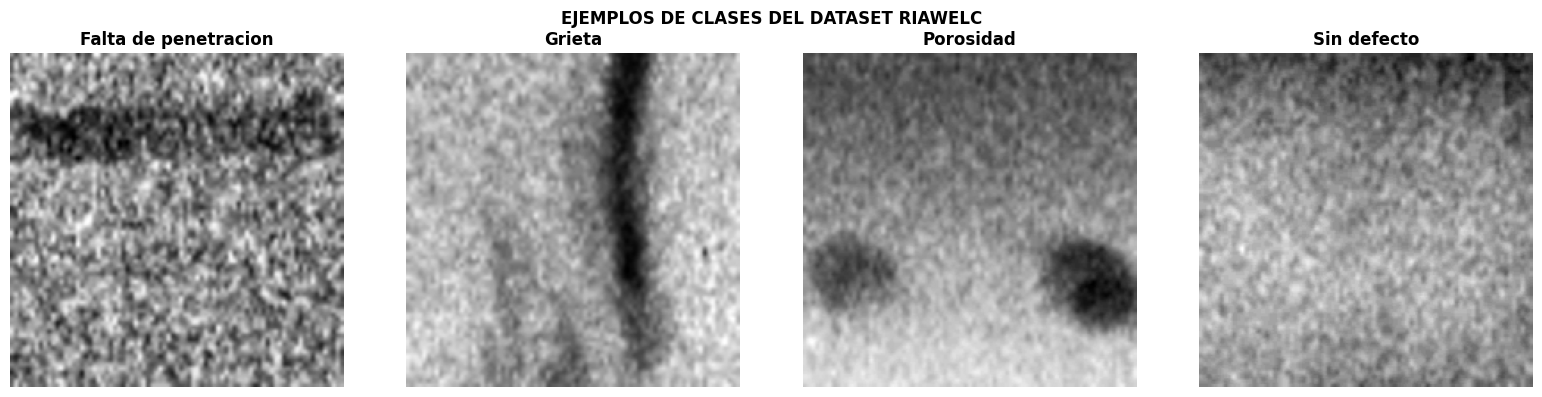

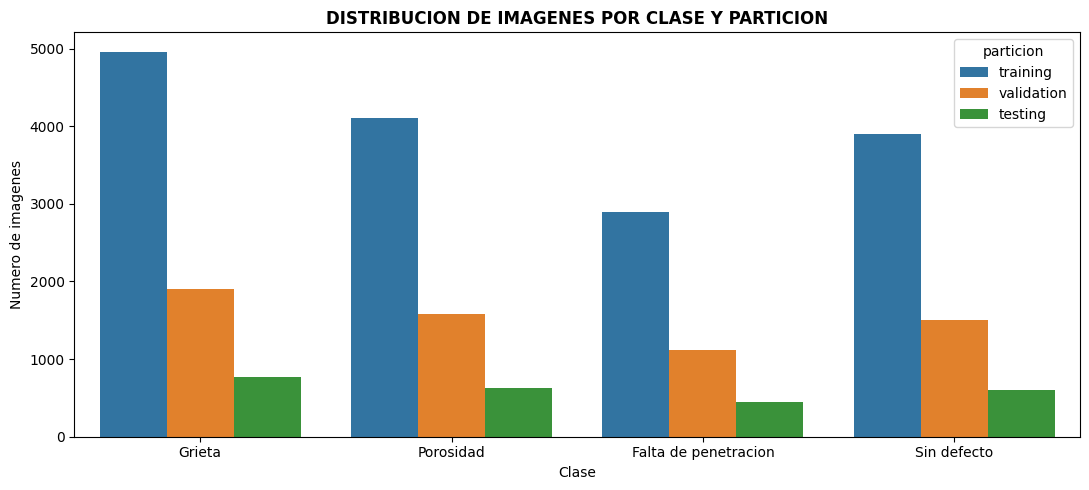

In [2]:
# INVENTARIO Y EXPLORACION DEL DATASET

registros = []
for particion in ["training", "validation", "testing"]:
    for carpeta, clase in MAPEO_CLASES.items():
        for imagen in (RUTA_DATASET / particion / carpeta).glob("*.png"):
            registros.append({"archivo": imagen.name, "ruta": str(imagen), "particion": particion, "clase": clase})

df_inventario = pd.DataFrame(registros)
resumen_origen = df_inventario.groupby(["particion", "clase"]).size().reset_index(name="imagenes")
display(resumen_origen)
print(f"Total de imagenes originales: {len(df_inventario):,}")

muestras_visuales = df_inventario[df_inventario["particion"] == "training"].groupby("clase", group_keys=False).sample(n=1, random_state=42).sort_values("clase")
fig, ejes = plt.subplots(1, 4, figsize=(16, 4))
for eje, (_, fila) in zip(ejes, muestras_visuales.iterrows()):
    eje.imshow(Image.open(fila["ruta"]).convert("L"), cmap="gray")
    eje.set_title(fila["clase"], fontweight="bold")
    eje.axis("off")
plt.suptitle("EJEMPLOS DE CLASES DEL DATASET RIAWELC", fontweight="bold")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
sns.countplot(data=df_inventario, x="clase", hue="particion", order=NOMBRES_CLASES)
plt.title("DISTRIBUCION DE IMAGENES POR CLASE Y PARTICION", fontweight="bold")
plt.xlabel("Clase")
plt.ylabel("Numero de imagenes")
plt.tight_layout()
plt.show()

In [3]:
# MUESTREO, LIMPIEZA Y ESTANDARIZACION

TAMANOS_MUESTRA = {"training": 300, "validation": 100, "testing": 100}
muestras = []
for particion, cantidad in TAMANOS_MUESTRA.items():
    for clase in NOMBRES_CLASES:
        grupo = df_inventario[(df_inventario["particion"] == particion) & (df_inventario["clase"] == clase)]
        muestras.append(grupo.sample(n=cantidad, random_state=42))
df_muestra = pd.concat(muestras, ignore_index=True)
display(df_muestra.groupby(["particion", "clase"]).size().reset_index(name="imagenes"))

imagenes, etiquetas, particiones, archivos, errores = [], [], [], [], []
for _, fila in tqdm(df_muestra.iterrows(), total=len(df_muestra), desc="Limpiando imagenes"):
    try:
        with Image.open(fila["ruta"]) as imagen:
            imagen = ImageOps.exif_transpose(imagen).convert("L").resize((64, 64), Image.Resampling.LANCZOS)
            imagenes.append(np.asarray(imagen, dtype=np.uint8))
            etiquetas.append(CLASE_A_ID[fila["clase"]])
            particiones.append(fila["particion"])
            archivos.append(fila["archivo"])
    except Exception as error:
        errores.append({"ruta": fila["ruta"], "error": str(error)})

X = np.stack(imagenes)
y = np.array(etiquetas)
particiones = np.array(particiones)
archivos = np.array(archivos)
np.savez_compressed(RUTA_DATOS_LIMP / "riawelc_muestra_limpia_64x64.npz", X=X, y=y, particiones=particiones, archivos=archivos)
pd.DataFrame({"archivo": archivos, "etiqueta": y, "particion": particiones}).to_csv(RUTA_DATOS_LIMP / "manifest_muestra_limpia.csv", index=False, encoding="utf-8-sig")
print(f"Imagenes procesadas correctamente: {len(X):,}")
print(f"Imagenes con error: {len(errores):,}")
print("Forma del arreglo limpio:", X.shape)

,particion,clase,imagenes
0,testing,Falta de penetracion,100
1,testing,Grieta,100
2,testing,Porosidad,100
3,testing,Sin defecto,100
4,training,Falta de penetracion,300
5,training,Grieta,300
6,training,Porosidad,300
7,training,Sin defecto,300
8,validation,Falta de penetracion,100
9,validation,Grieta,100


Limpiando imagenes:   0%|          | 0/2000 [00:00<?, ?it/s]

Imagenes procesadas correctamente: 2,000
Imagenes con error: 0
Forma del arreglo limpio: (2000, 64, 64)


In [4]:
# EXTRACCION DE CARACTERISTICAS Y DIVISION DE DATOS

def extraer_hog(imagen):
    return hog(imagen / 255.0, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")

X_hog = np.array([extraer_hog(imagen) for imagen in tqdm(X, desc="Extrayendo caracteristicas HOG")])
X_train, y_train = X_hog[particiones == "training"], y[particiones == "training"]
X_val, y_val = X_hog[particiones == "validation"], y[particiones == "validation"]
X_test, y_test = X_hog[particiones == "testing"], y[particiones == "testing"]
print("Caracteristicas por imagen:", X_hog.shape[1])
print("Entrenamiento:", X_train.shape)
print("Validacion:", X_val.shape)
print("Prueba:", X_test.shape)

Extrayendo caracteristicas HOG:   0%|          | 0/2000 [00:00<?, ?it/s]

Caracteristicas por imagen: 324
Entrenamiento: (1200, 324)
Validacion: (400, 324)
Prueba: (400, 324)


In [5]:
# CONFIGURACION DE MLFLOW

from mlflow.tracking import MlflowClient

RUTA_MLFLOW = RUTA_PROYECTO / "mlruns"
RUTA_ARTEFACTOS = RUTA_MLFLOW / "artefactos"
RUTA_MLFLOW.mkdir(exist_ok=True)
RUTA_ARTEFACTOS.mkdir(exist_ok=True)
URI_TRACKING = f"sqlite:///{RUTA_MLFLOW / 'mlflow.db'}"
NOMBRE_EXPERIMENTO = "Actividad5_Vision360_RIAWELC"
mlflow.set_tracking_uri(URI_TRACKING)
cliente = MlflowClient()
if cliente.get_experiment_by_name(NOMBRE_EXPERIMENTO) is None:
    cliente.create_experiment(NOMBRE_EXPERIMENTO, artifact_location=RUTA_ARTEFACTOS.as_uri())
mlflow.set_experiment(NOMBRE_EXPERIMENTO)
print("MLflow configurado correctamente")

MLflow configurado correctamente


In [6]:
# ENTRENAMIENTO Y AJUSTE DE HIPERPARAMETROS

def calcular_metricas(y_real, y_predicho, probabilidades):
    return {
        "accuracy": accuracy_score(y_real, y_predicho),
        "precision_macro": precision_score(y_real, y_predicho, average="macro", zero_division=0),
        "recall_macro": recall_score(y_real, y_predicho, average="macro", zero_division=0),
        "f1_macro": f1_score(y_real, y_predicho, average="macro", zero_division=0),
        "roc_auc_ovr_weighted": roc_auc_score(y_real, probabilidades, multi_class="ovr", average="weighted")
    }

cv_estratificada = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

configuraciones = {
    "Regresion Logistica": (
        Pipeline([("escalado", StandardScaler()), ("modelo", LogisticRegression(max_iter=2000, solver="lbfgs", random_state=42))]),
        {"modelo__C": [0.1, 1.0, 10.0], "modelo__class_weight": [None, "balanced"]}
    ),
    "Random Forest": (
        Pipeline([("modelo", RandomForestClassifier(random_state=42, n_jobs=1))]),
        {"modelo__n_estimators": [100, 200], "modelo__max_depth": [None, 20], "modelo__min_samples_split": [2, 5]}
    )
}

modelos, grids, resultados_validacion = {}, {}, []
for nombre, (pipeline, parametros) in configuraciones.items():
    grid = GridSearchCV(pipeline, parametros, scoring="f1_macro", cv=cv_estratificada, n_jobs=-1, return_train_score=True)
    with mlflow.start_run(run_name=f"{nombre.replace(' ', '_')}_GridSearch"):
        grid.fit(X_train, y_train)
        modelo = grid.best_estimator_
        metricas = calcular_metricas(y_val, modelo.predict(X_val), modelo.predict_proba(X_val))
        mlflow.log_params({"modelo": nombre, "caracteristicas": "HOG", "tamano_imagen": "64x64", "cv_folds": 3, **{f"mejor_{k.replace('modelo__', '')}": str(v) for k, v in grid.best_params_.items()}})
        mlflow.log_metric("cv_mejor_f1_macro", grid.best_score_)
        mlflow.log_metrics({f"validacion_{k}": v for k, v in metricas.items()})
        mlflow.log_dict({"mejores_parametros": grid.best_params_, "mejor_f1_cv": grid.best_score_}, f"resultados_{nombre.replace(' ', '_').lower()}.json")
        if nombre == "Random Forest":
            mlflow.sklearn.log_model(modelo, name="modelo", serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE)
        else:
            mlflow.sklearn.log_model(modelo, name="modelo")
    modelos[nombre], grids[nombre] = modelo, grid
    resultados_validacion.append({"modelo": nombre, "f1_cv_media": grid.best_score_, "f1_cv_desviacion": grid.cv_results_["std_test_score"][grid.best_index_], **metricas})

df_validacion = pd.DataFrame(resultados_validacion)
display(df_validacion.round(4))

2026/10/19 16:47:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,modelo,f1_cv_media,f1_cv_desviacion,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_weighted
0,Regresion Logistica,0.5519,0.0178,0.5700,0.5634,0.5700,0.5650,0.8112
1,Random Forest,0.6567,0.0109,0.6575,0.6586,0.6575,0.6534,0.8790


,modelo,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_weighted
0,Regresion Logistica,0.5700,0.5572,0.5700,0.5611,0.8028
1,Random Forest,0.6675,0.6672,0.6675,0.6627,0.8858


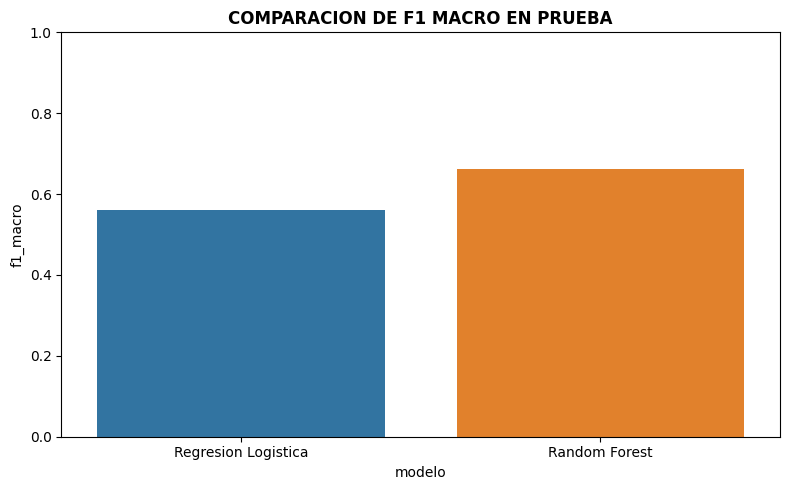

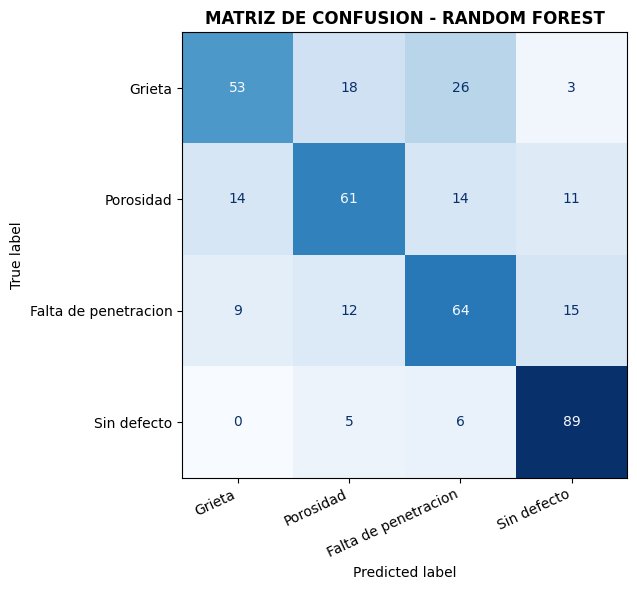

,precision,recall,f1-score,support
Grieta,0.6974,0.5300,0.6023,100.0000
Porosidad,0.6354,0.6100,0.6224,100.0000
Falta de penetracion,0.5818,0.6400,0.6095,100.0000
Sin defecto,0.7542,0.8900,0.8165,100.0000
accuracy,0.6675,0.6675,0.6675,0.6675
macro avg,0.6672,0.6675,0.6627,400.0000
weighted avg,0.6672,0.6675,0.6627,400.0000


Modelo seleccionado: Random Forest


In [9]:
# COMPARACION Y EVALUACION FINAL

resultados_prueba = []
for nombre, modelo in modelos.items():
    prediccion = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)
    metricas = calcular_metricas(y_test, prediccion, probabilidades)
    resultados_prueba.append({"modelo": nombre, **metricas})
    with mlflow.start_run(run_name=f"Evaluacion_Prueba_{nombre.replace(' ', '_')}"):
        mlflow.log_param("modelo_evaluado", nombre)
        mlflow.log_metrics({f"prueba_{k}": v for k, v in metricas.items()})

df_prueba = pd.DataFrame(resultados_prueba)
display(df_prueba.round(4))
df_validacion.to_csv(RUTA_RESULTADOS / "comparacion_modelos_validacion.csv", index=False, encoding="utf-8-sig")
df_prueba.to_csv(RUTA_RESULTADOS / "comparacion_modelos_prueba.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(8, 5))
sns.barplot(data=df_prueba, x="modelo", y="f1_macro", hue="modelo", legend=False)
plt.title("COMPARACION DE F1 MACRO EN PRUEBA", fontweight="bold")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

modelo_seleccionado = df_validacion.loc[df_validacion["f1_macro"].idxmax(), "modelo"]
pred_final = modelos[modelo_seleccionado].predict(X_test)
matriz = confusion_matrix(y_test, pred_final, labels=[0, 1, 2, 3])
figura, eje = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(matriz, display_labels=NOMBRES_CLASES).plot(ax=eje, cmap="Blues", colorbar=False)
plt.title(f"MATRIZ DE CONFUSION - {modelo_seleccionado.upper()}", fontweight="bold")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

reporte_por_clase = pd.DataFrame(classification_report(y_test, pred_final, target_names=NOMBRES_CLASES, output_dict=True, zero_division=0)).transpose()
display(reporte_por_clase.round(4))
reporte_por_clase.to_csv(RUTA_RESULTADOS / "reporte_clasificacion_modelo_seleccionado.csv", encoding="utf-8-sig")
print("Modelo seleccionado:", modelo_seleccionado)

In [10]:
# MODELO FINAL Y EVIDENCIA DE MLFLOW

X_final = np.vstack([X_train, X_val])
y_final = np.concatenate([y_train, y_val])
modelo_final = clone(modelos[modelo_seleccionado]).fit(X_final, y_final)
RUTA_MODELOS = RUTA_RESULTADOS / "modelos"
RUTA_MODELOS.mkdir(exist_ok=True)
joblib.dump(modelo_final, RUTA_MODELOS / "random_forest_vision360.joblib")

with mlflow.start_run(run_name="Modelo_Final_Seleccionado"):
    mlflow.log_param("modelo", modelo_seleccionado)
    mlflow.log_param("imagenes_entrenamiento_final", len(X_final))
    mlflow.log_metric("referencia_prueba_f1_macro", float(df_prueba.loc[df_prueba["modelo"] == modelo_seleccionado, "f1_macro"].iloc[0]))
    mlflow.sklearn.log_model(modelo_final, name="modelo_final", serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE)

experimento = mlflow.get_experiment_by_name(NOMBRE_EXPERIMENTO)
runs = mlflow.search_runs(experiment_ids=[experimento.experiment_id], output_format="pandas")
columnas = [c for c in ["tags.mlflow.runName", "status", "metrics.cv_mejor_f1_macro", "metrics.validacion_f1_macro", "metrics.prueba_f1_macro", "params.modelo"] if c in runs.columns]
evidencia_mlflow = runs[columnas].rename(columns={"tags.mlflow.runName": "Corrida MLflow", "status": "Estado", "metrics.cv_mejor_f1_macro": "F1 CV", "metrics.validacion_f1_macro": "F1 validacion", "metrics.prueba_f1_macro": "F1 prueba", "params.modelo": "Modelo"})
display(evidencia_mlflow.sort_values("Corrida MLflow").style.set_caption("EVIDENCIA DE REGISTRO DE EXPERIMENTOS EN MLFLOW").format(precision=4, na_rep="-"))
evidencia_mlflow.to_csv(RUTA_RESULTADOS / "evidencia_registros_mlflow.csv", index=False, encoding="utf-8-sig")

2026/10/19 16:50:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,Corrida MLflow,Estado,F1 CV,F1 validacion,F1 prueba,Modelo
1,Evaluacion_Prueba_Random_Forest,FINISHED,-,-,0.6627,-
4,Evaluacion_Prueba_Random_Forest,FINISHED,-,-,0.6627,-
16,Evaluacion_Prueba_Random_Forest,FINISHED,-,-,0.6372,-
8,Evaluacion_Prueba_Random_Forest,FINISHED,-,-,0.6627,-
11,Evaluacion_Prueba_Random_Forest,FINISHED,-,-,0.6627,-
2,Evaluacion_Prueba_Regresion_Logistica,FINISHED,-,-,0.5611,-
5,Evaluacion_Prueba_Regresion_Logistica,FINISHED,-,-,0.5611,-
12,Evaluacion_Prueba_Regresion_Logistica,FINISHED,-,-,0.5611,-
9,Evaluacion_Prueba_Regresion_Logistica,FINISHED,-,-,0.5611,-
17,Evaluacion_Prueba_Regresion_logistica,FINISHED,-,-,0.5611,-


In [36]:
# ACCESO AL PANEL DE MLFLOW

from pathlib import Path
from urllib.parse import urlparse
import json
import subprocess
import time
import urllib.request
from google.colab import output
import mlflow

proyecto = Path("/content/drive/MyDrive/Actividad5_Vision360")
base_mlflow = proyecto / "mlruns" / "mlflow.db"
puerto = 5014

host_interno = (
    "m-s-kkb-usc1a2-3p7o1q7yfao1m."
    "us-central1-a.c.codatalab-user-runtimes.internal:8007"
)

url_colab = output.eval_js(f"google.colab.kernel.proxyPort({puerto})")
partes_url = urlparse(url_colab)
origen_colab = f"{partes_url.scheme}://{partes_url.netloc}"

print("Origen de Colab:", origen_colab)

mlflow.set_tracking_uri(f"sqlite:///{base_mlflow}")
experimento = mlflow.get_experiment_by_name(
    "Actividad5_Vision360_RIAWELC"
)

if experimento is None:
    raise ValueError("No se encontro el experimento")

if "proceso_mlflow" in globals() and proceso_mlflow.poll() is None:
    proceso_mlflow.terminate()
    proceso_mlflow.wait(timeout=15)

archivo_log = Path("/tmp/mlflow_panel_corregido.log")
registro = archivo_log.open("w")

proceso_mlflow = subprocess.Popen(
    [
        "mlflow", "server",
        "--backend-store-uri", f"sqlite:///{base_mlflow}",
        "--host", "127.0.0.1",
        "--port", str(puerto),
        "--workers", "1",
        "--allowed-hosts", f"localhost:*,127.0.0.1:*,{host_interno}",
        "--cors-allowed-origins", origen_colab,
        "--x-frame-options", "NONE"
    ],
    stdout=registro,
    stderr=subprocess.STDOUT
)

registro.close()

consulta = json.dumps({
    "experiment_ids": [experimento.experiment_id],
    "max_results": 1
}).encode("utf-8")

respuesta_correcta = False
ultimo_error = None

for intento in range(30):
    if proceso_mlflow.poll() is not None:
        break

    solicitud = urllib.request.Request(
        f"http://127.0.0.1:{puerto}/ajax-api/2.0/mlflow/runs/search",
        data=consulta,
        method="POST",
        headers={
            "Host": host_interno,
            "Origin": origen_colab,
            "Content-Type": "application/json"
        }
    )

    try:
        with urllib.request.urlopen(solicitud, timeout=3) as respuesta:
            print("Consulta de corridas:", respuesta.status)
            respuesta_correcta = True
        break

    except Exception as error:
        ultimo_error = error
        time.sleep(1)

if respuesta_correcta:
    print("El panel debe aparecer debajo.")
    output.serve_kernel_port_as_iframe(puerto, height=700)
else:
    print("No se pudo completar la consulta:", ultimo_error)
    print("\nREGISTRO DEL SERVIDOR:")
    print(archivo_log.read_text(encoding="utf-8", errors="replace")[-3000:])

Origen de Colab: https://5014-m-s-kkb-usc1a2-3p7o1q7yfao1m-a.us-central1-2.prod.colab.dev
Consulta de corridas: 200
El panel debe aparecer debajo.


<IPython.core.display.Javascript object>

In [ ]:
# CREACION DEL PRIMER COMMIT LOCAL

from pathlib import Path
import subprocess

proyecto = Path("/content/drive/MyDrive/Actividad5_Vision360/Actividad5")

def ejecutar_git(*argumentos):
    resultado = subprocess.run(
        ["git", *argumentos],
        cwd=proyecto,
        capture_output=True,
        text=True
    )

    if resultado.returncode != 0:
        raise RuntimeError(resultado.stderr.strip() or resultado.stdout.strip())

    return resultado.stdout.strip()

# PREPARAR LOS ARCHIVOS PARA EL COMMIT
ejecutar_git("add", "--all")

archivos_preparados = ejecutar_git("diff", "--cached", "--name-only").splitlines()

print("ARCHIVOS PREPARADOS:", len(archivos_preparados))

if archivos_preparados:
    # CREAR EL PRIMER REGISTRO DE VERSION
    ejecutar_git("commit", "-m", "Version inicial de la actividad 5 Vision 360")
    ejecutar_git("branch", "-M", "main")

    print("\nCOMMIT CREADO CORRECTAMENTE")
    print(ejecutar_git("log", "-1", "--oneline"))
else:
    print("\nNO HAY ARCHIVOS NUEVOS PARA REGISTRAR")

print("\nESTADO DEL REPOSITORIO:")
estado = ejecutar_git("status", "--short")
print(estado if estado else "Sin cambios pendientes")